# Exploration — Industrial Performance Analytics

> Données réelles **PIADE** (Univ. Padoue, CC BY 4.0). `pi`/`po` sont des compteurs cumulés : l'écart entrées/sorties n'est qu'indicatif.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display
from src.ingestion.load import load_raw
from src.cleaning.clean import clean, profile_raw
from src.transformations.kpi import compute_kpis
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

## 1. Chargement et profil du brut

In [2]:
raw = load_raw(ROOT / 'data/raw', 'real')
print(raw.shape)
raw.head()

(429394, 13)


,interval_start,equipment_ID,alarm,type,start,end,elapsed,pi,po,speed,flag_counter_reset,flag_counter_gap,flag_counter_jump
0,2020-01-01 11:21:28.907,s_1,A_000,scheduled_downtime,2020-01-01 11:21:28.907,2020-01-01 11:22:31.957,63.050,0,0,0,False,True,False
1,2020-01-01 11:22:31.957,s_1,A_000,idle,2020-01-01 11:22:31.957,2020-01-01 11:23:02.797,30.840,0,0,0,False,False,False
2,2020-01-01 11:23:02.797,s_1,A_000,scheduled_downtime,2020-01-01 11:23:02.797,2020-01-01 11:46:33.468,1410.671,0,0,0,False,False,False
3,2020-01-01 11:46:33.468,s_1,A_000,idle,2020-01-01 11:46:33.468,2020-01-01 12:11:57.988,1524.520,0,0,0,False,False,False
4,2020-01-01 12:11:57.988,s_1,A_000,scheduled_downtime,2020-01-01 12:11:57.988,2020-01-01 12:59:09.258,2831.270,0,0,0,False,False,False


In [3]:
p = profile_raw(raw)
print('doublons exacts :', p['exact_duplicates'])
pd.Series(p['missing'], name='manquants').to_frame().T

doublons exacts : 0


,interval_start,equipment_ID,alarm,type,start,end,elapsed,pi,po,speed,flag_counter_reset,flag_counter_gap,flag_counter_jump
manquants,0,0,0,0,0,0,0,0,0,0,0,0,0


In [4]:
raw['type'].value_counts()

type
production            146795
performance_loss      118584
downtime               92084
idle                   50149
scheduled_downtime     21782
Name: count, dtype: Int64

## 2. Nettoyage (règles R1–R10, voir `docs/cleaning_rules.md`)

In [5]:
res = clean(raw, quantities='increments')
pd.Series(res.report['rules'], name='lignes concernées').to_frame()

,lignes concernées
R1_exact_duplicates_dropped,0
R1b_conflicting_duplicate,0
R2_unknown_type,0
R3_unparsable_date_or_missing_machine,0
R4_end_before_start,0
R6_negative_quantity,0
R7_po_gt_pi_flagged_kept,65633
R5_elapsed_recomputed,0
R8_downtime_alarm_set_unknown,0
R9_overlap_flagged,6


In [6]:
print('conservation brut = propre + rejeté + doublons :', res.report['conservation_ok'])
res.rejected['reject_reason'].value_counts()

conservation brut = propre + rejeté + doublons : True


Series([], Name: count, dtype: int64)

## 3. KPI par machine

In [7]:
k = compute_kpis(res.clean, ['equipment_ID'])
k[['equipment_ID','input_units','output_units','defect_rate','availability','avg_downtime_min','performance_index','oee_proxy']].round(4)

,equipment_ID,input_units,output_units,defect_rate,availability,avg_downtime_min,performance_index,oee_proxy
0,s_1,34679730,34535156,0.0042,0.8690,2.5634,0.8244,0.7134
1,s_2,8337448,8292863,0.0053,0.7498,1.9830,0.7459,0.5563
2,s_3,12018294,11989674,0.0024,0.8771,3.5846,0.8028,0.7025
3,s_4,15539578,15432946,0.0069,0.9220,1.1782,0.5937,0.5436
4,s_5,28921134,28846240,0.0026,0.9408,1.3290,0.7871,0.7386


Rappel : `performance_index` est **relatif** (vitesse nominale = P95 empirique) et `oee_proxy` égale algébriquement le taux de réalisation de la référence (voir `docs/kpi_definitions.md`).

## 4. Figures commentées
Le commentaire (question, méthode, résultat, limites) est dans `reports/eda_summary.md`.

fig01_production_daily_weekly.png


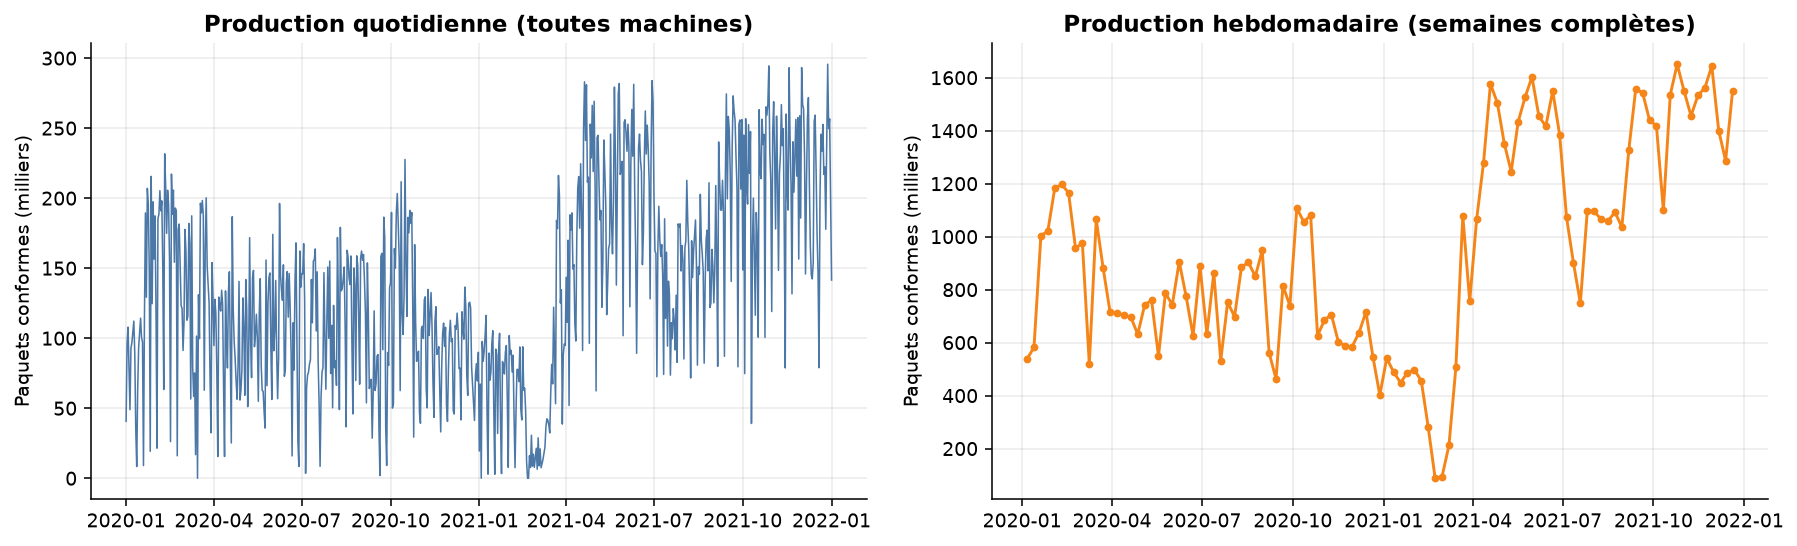

fig02_downtime_machine_cause.png


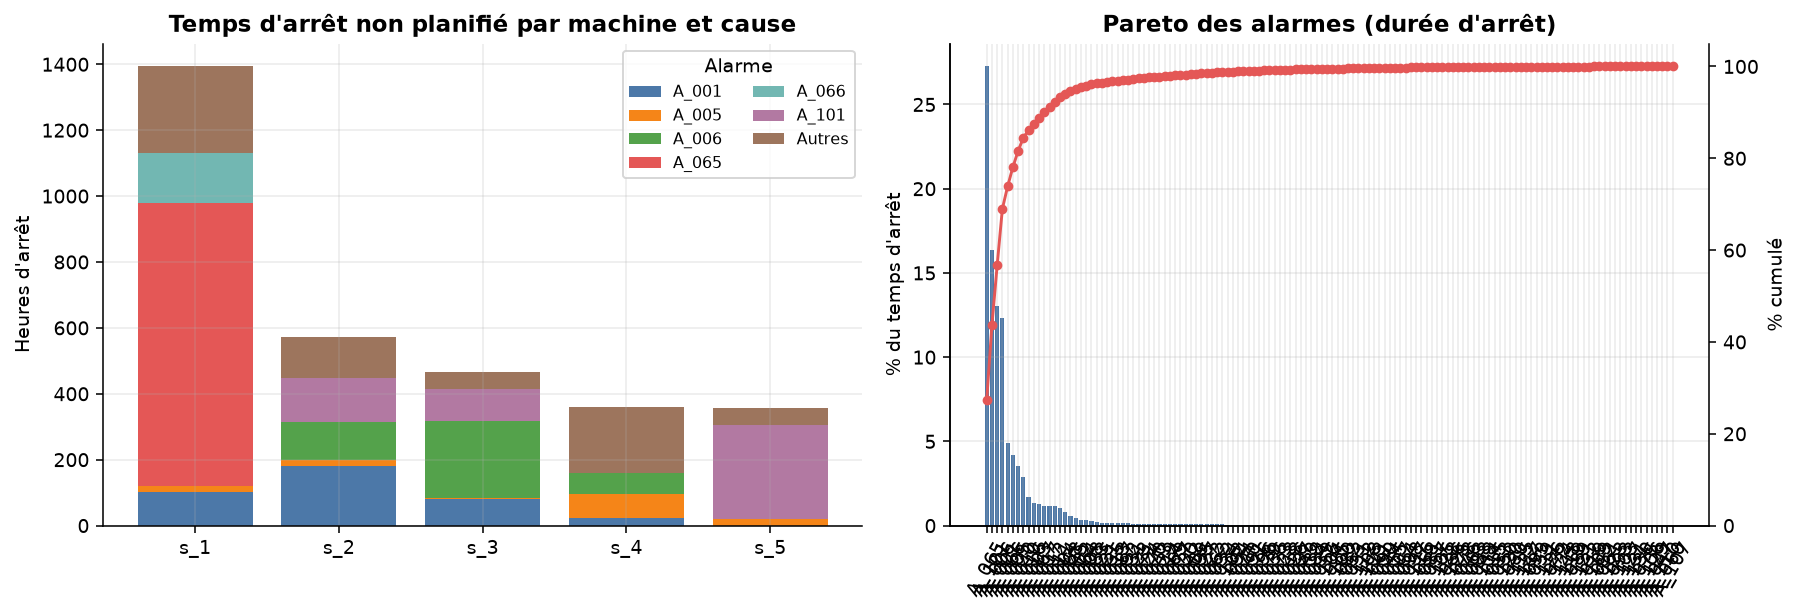

fig03_defect_rate.png


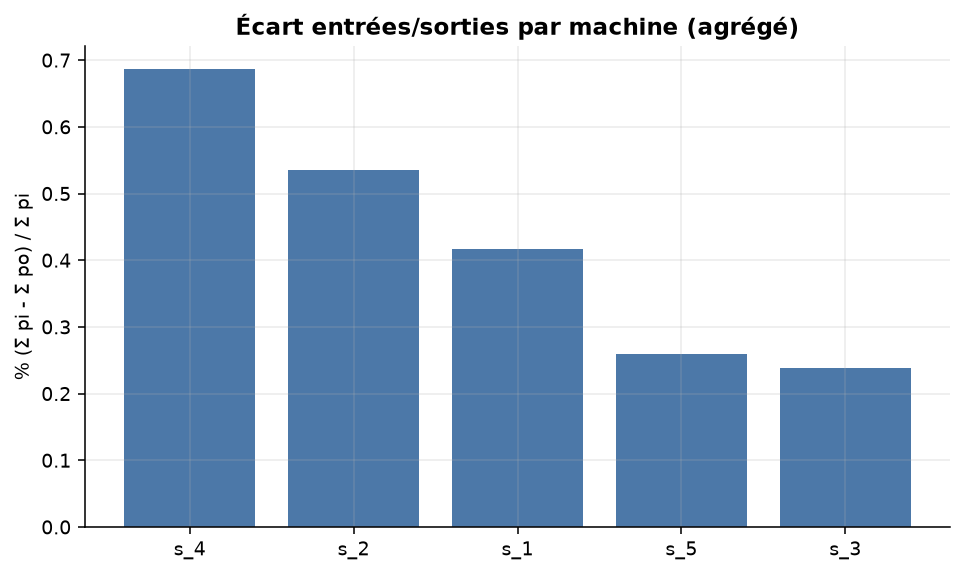

fig04_output_vs_reference.png


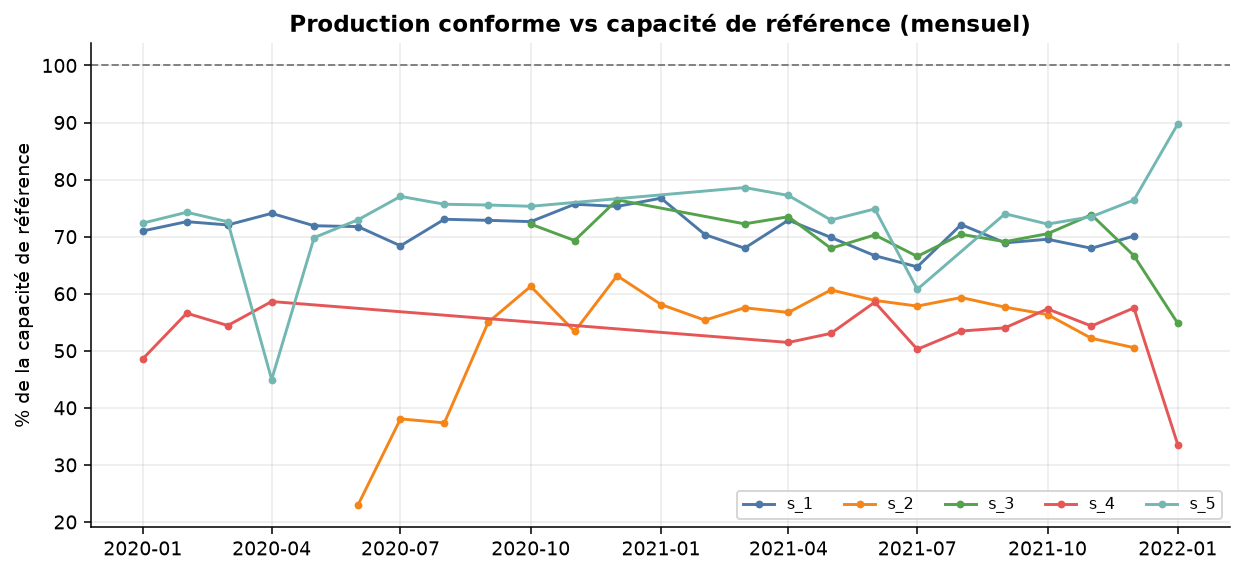

fig05_downtime_duration_dist.png


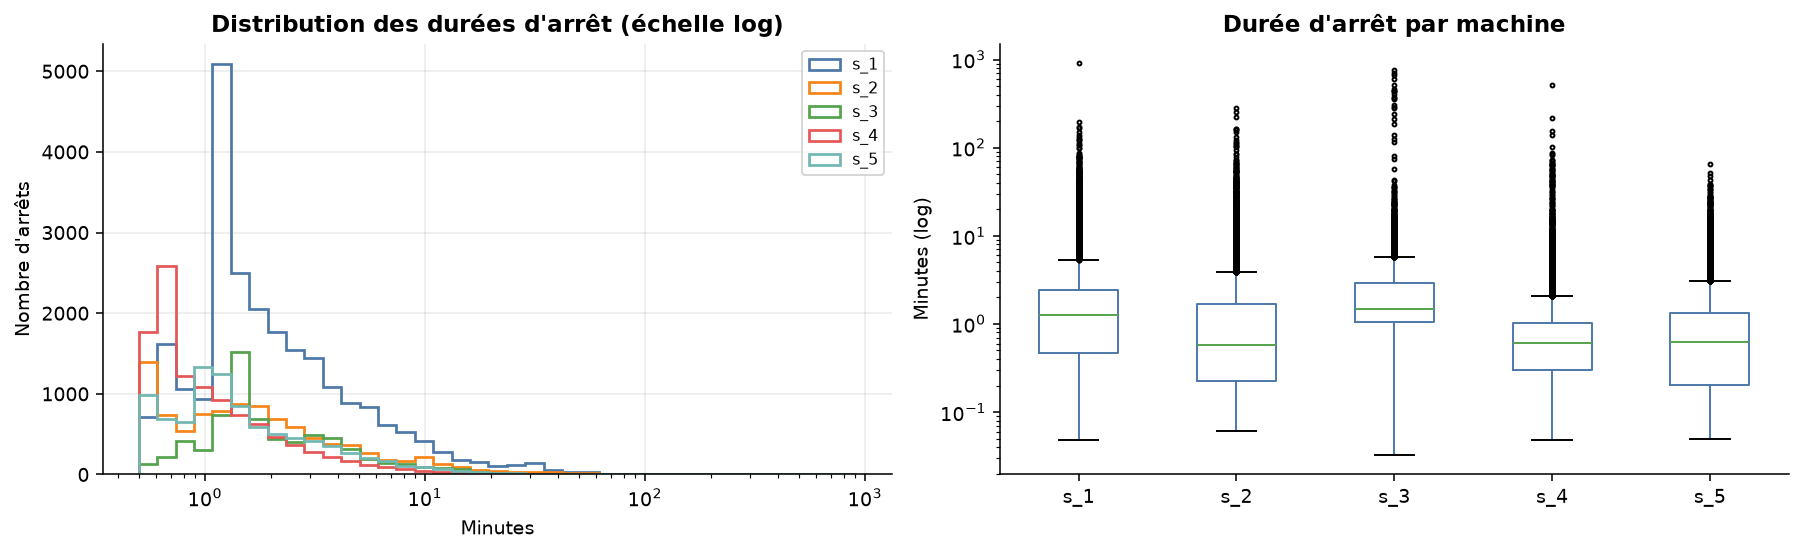

fig06_availability_heatmap.png


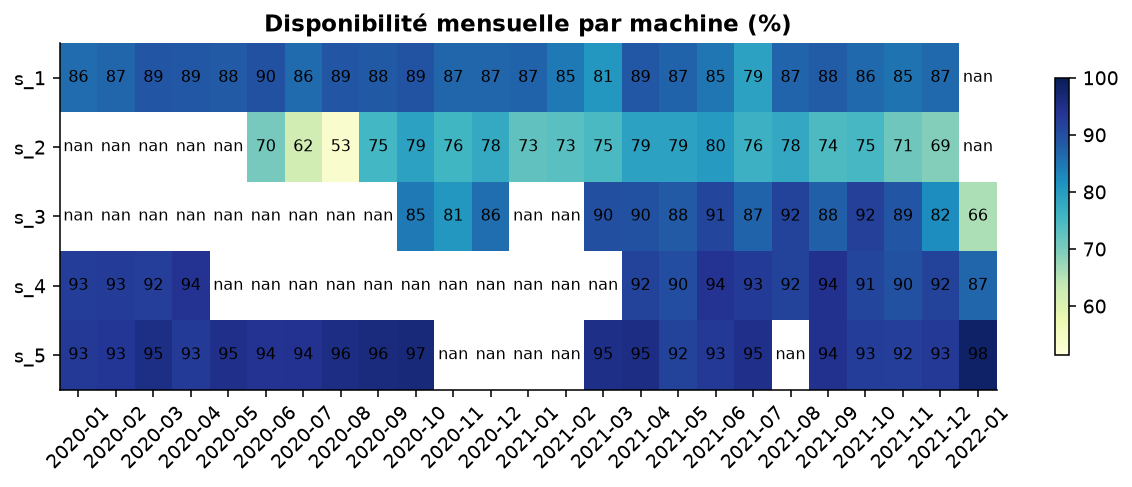

fig07_downtime_hour_weekday.png


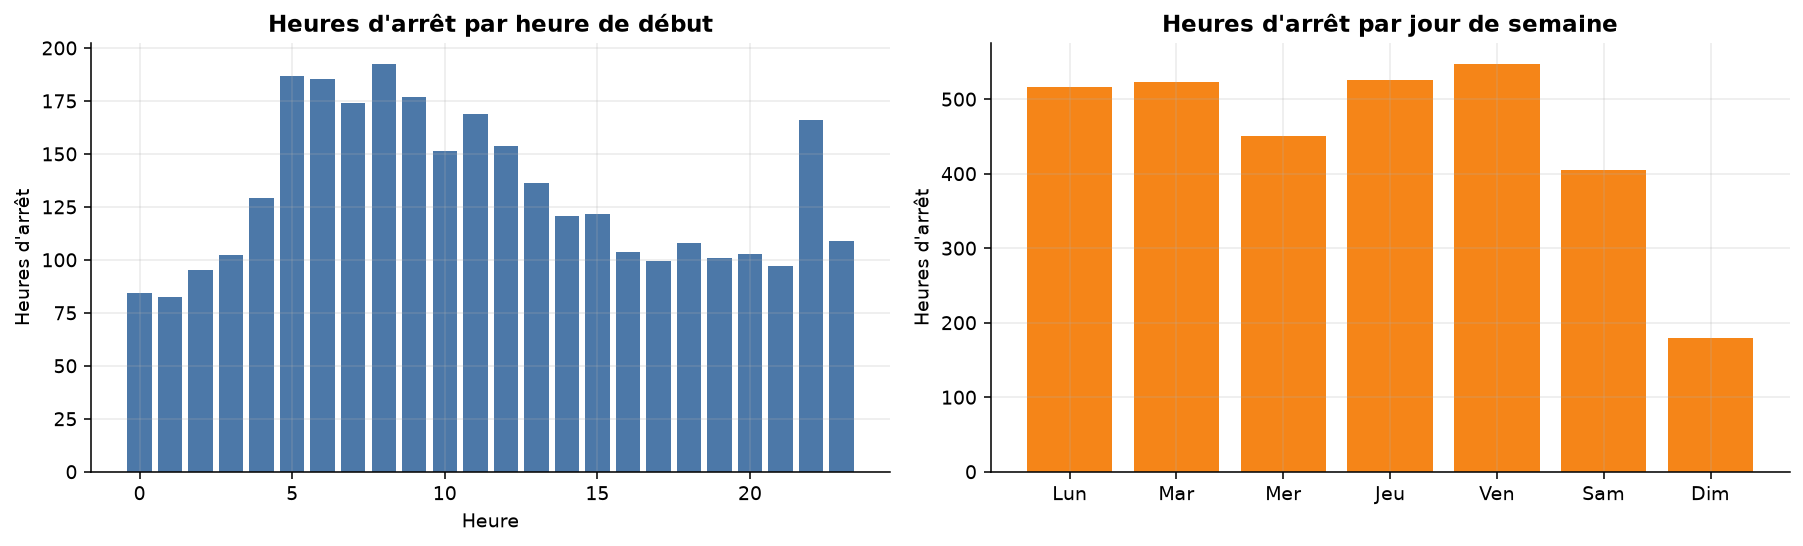

In [8]:
for f in sorted((ROOT / 'reports/figures').glob('fig*.png')):
    print(f.name)
    display(Image(filename=str(f)))